# Unsupervised Analysis of the Indian Pines Hyperspectral Image
**PCA → NMF unmixing → K-Means / GMM / Ward / HDBSCAN clustering → label-free evaluation**

No ground-truth labels are needed anywhere in this notebook. Accuracy, Kappa and confusion matrices
cannot be computed without labels, so the methods are compared with **internal cluster-quality indices,
spatial coherence, run-to-run stability and agreement between methods** instead.

Pipeline
1. Load the cube from `indian_pines.csv` (`row`, `col`, `band_1` … `band_200`)
2. Explore the data
3. Dimensionality reduction: PCA (and t-SNE for visualisation)
4. Spectral unmixing with NMF (endmembers + abundance maps)
5. Choosing the number of clusters
6. Clustering: K-Means, brightness-normalised K-Means, Gaussian Mixture, spatially-constrained Ward, spatial-spectral K-Means, HDBSCAN
7. Label-free evaluation, method agreement, cluster maps and cluster spectra
8. Export results

**Files:** only `indian_pines.csv` is required (the notebook falls back to `Indian_pines_corrected.mat` / its `.zip` if the CSV is absent).

## 1. Setup and data loading

In [1]:
import os, time, zipfile, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.feature_extraction.image import grid_to_graph
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
try:
    from sklearn.cluster import HDBSCAN          # scikit-learn >= 1.3
    HDBSCAN_OK = True
except Exception:
    HDBSCAN_OK = False

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110
H, W = 145, 145
N = H * W

In [2]:
CSV_FILE = "indian_pines.csv"
MAT_FILE = "Indian_pines_corrected.mat"
ZIP_FILE = "Indian_pines_corrected_mat.zip"

if os.path.exists(CSV_FILE):
    df = pd.read_csv(CSV_FILE)
    band_cols = sorted([c for c in df.columns if c.startswith("band_")], key=lambda x: int(x.split("_")[1]))
    assert {"row", "col"}.issubset(df.columns), "CSV must contain 'row' and 'col' columns."
    assert len(df) == N, f"Expected {N} pixels, found {len(df)}."
    assert not df.duplicated(["row", "col"]).any(), "Duplicate row/col pairs in CSV."
    cube = np.empty((H, W, len(band_cols)), dtype=np.float32)
    cube[df["row"].astype(int).to_numpy(), df["col"].astype(int).to_numpy(), :] = df[band_cols].to_numpy(np.float32)
    print(f"Loaded {CSV_FILE}")
else:
    if not os.path.exists(MAT_FILE) and os.path.exists(ZIP_FILE):
        zipfile.ZipFile(ZIP_FILE).extractall(".")
    assert os.path.exists(MAT_FILE), f"Neither {CSV_FILE} nor {MAT_FILE} found in the working directory."
    cube = sio.loadmat(MAT_FILE)["indian_pines_corrected"].astype(np.float32)
    print(f"Loaded {MAT_FILE}")

B = cube.shape[2]
X_all = cube.reshape(N, B)                         # one row per pixel
print("cube:", cube.shape, "| pixels x bands:", X_all.shape)
print(f"value range: {X_all.min():.0f} - {X_all.max():.0f} | NaNs: {int(np.isnan(X_all).sum())}")

Loaded indian_pines.csv
cube: (145, 145, 200) | pixels x bands: (21025, 200)
value range: 955 - 9604 | NaNs: 0


## 2. Exploring the data

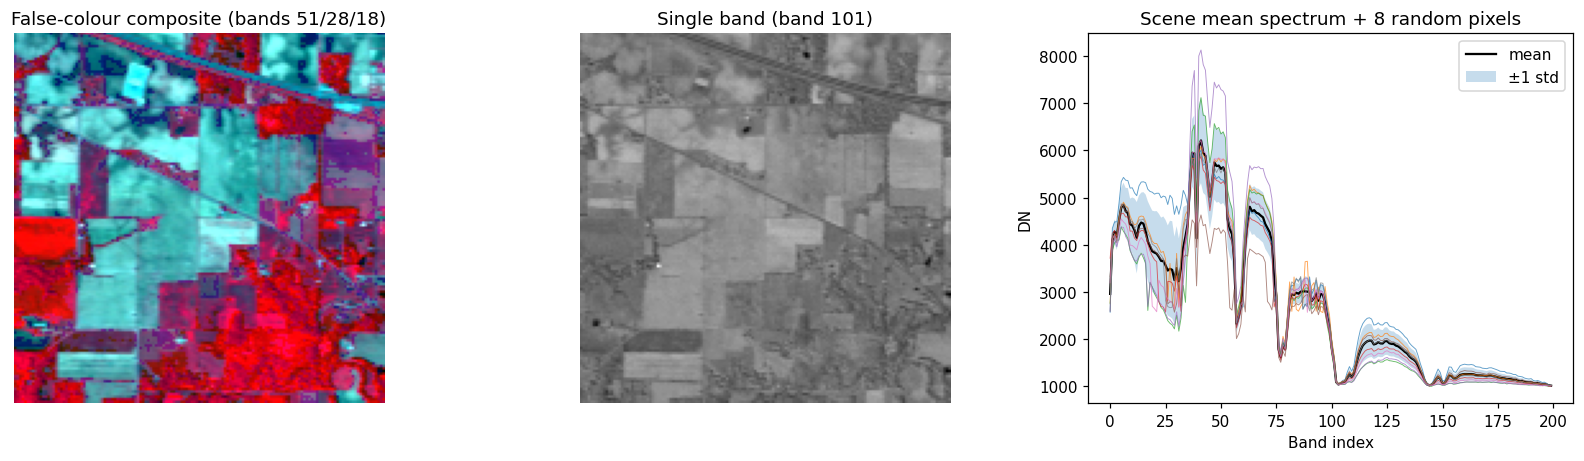

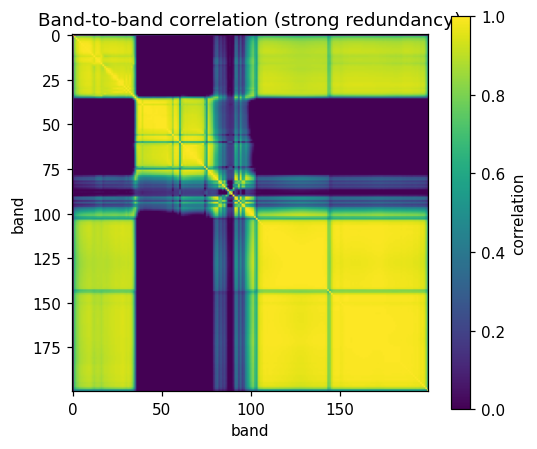

In [3]:
def false_colour(c, bands=(50, 27, 17)):
    rgb = c[:, :, list(bands)].copy()
    for i in range(3):
        lo, hi = np.percentile(rgb[:, :, i], (2, 98))
        rgb[:, :, i] = np.clip((rgb[:, :, i] - lo) / (hi - lo + 1e-9), 0, 1)
    return rgb

RGB = false_colour(cube)
rng = np.random.RandomState(SEED)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].imshow(RGB); ax[0].set_title("False-colour composite (bands 51/28/18)"); ax[0].axis("off")
ax[1].imshow(cube[:, :, 100], cmap="gray"); ax[1].set_title("Single band (band 101)"); ax[1].axis("off")
mu, sd = X_all.mean(0), X_all.std(0)
ax[2].plot(mu, c="k", label="mean"); ax[2].fill_between(range(B), mu - sd, mu + sd, alpha=.25, label="±1 std")
for i in rng.choice(N, 8, replace=False): ax[2].plot(X_all[i], lw=.6, alpha=.7)
ax[2].set_xlabel("Band index"); ax[2].set_ylabel("DN"); ax[2].set_title("Scene mean spectrum + 8 random pixels"); ax[2].legend()
plt.tight_layout(); plt.show()

corr = np.corrcoef(X_all.T)
plt.figure(figsize=(5, 4.3)); plt.imshow(corr, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="correlation"); plt.title("Band-to-band correlation (strong redundancy)")
plt.xlabel("band"); plt.ylabel("band"); plt.tight_layout(); plt.show()

## 3. Dimensionality reduction
### 3.1 PCA
Bands are standardised, then PCA compresses the 200 highly-correlated bands into a few components.

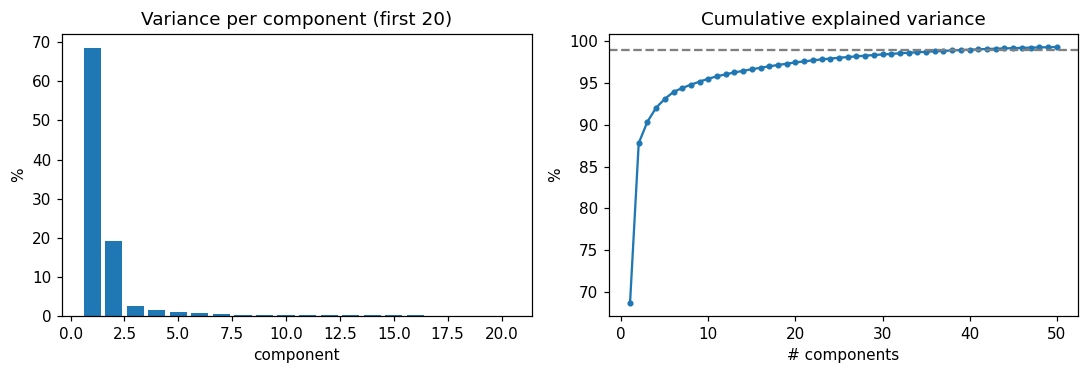

{90: 3, 95: 9, 99: 40} components for 90 / 95 / 99 % variance


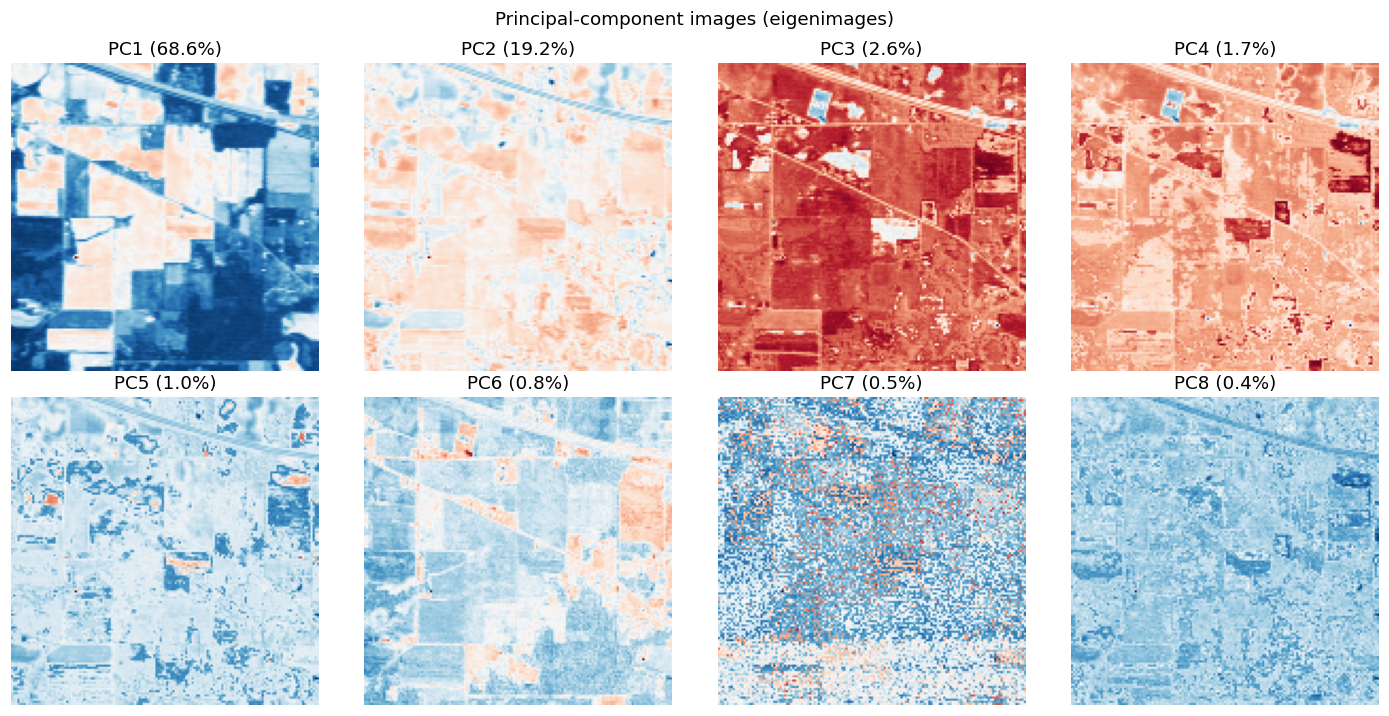

In [4]:
X_std = StandardScaler().fit_transform(X_all)
pca = PCA(n_components=50, random_state=SEED).fit(X_std)
cum = np.cumsum(pca.explained_variance_ratio_) * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(range(1, 21), pca.explained_variance_ratio_[:20] * 100); ax[0].set_title("Variance per component (first 20)")
ax[0].set_xlabel("component"); ax[0].set_ylabel("%")
ax[1].plot(range(1, 51), cum, marker="."); ax[1].axhline(99, ls="--", c="gray")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("# components"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()
print({k: int(np.searchsorted(cum, k) + 1) for k in (90, 95, 99)}, "components for 90 / 95 / 99 % variance")

N_PCA = 20
Z = pca.transform(X_std)[:, :N_PCA].astype(np.float32)          # (N, 20) features used for clustering
Z_img = Z.reshape(H, W, N_PCA)

fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for i, a in enumerate(ax.ravel()):
    a.imshow(Z_img[:, :, i], cmap="RdBu_r"); a.set_title(f"PC{i+1} ({pca.explained_variance_ratio_[i]*100:.1f}%)"); a.axis("off")
plt.suptitle("Principal-component images (eigenimages)"); plt.tight_layout(); plt.show()

### 3.2 Spatially smoothed features
Neighbouring pixels in a field usually belong to the same crop, so a light Gaussian smoothing of the PCA images
gives a simple **spectral-spatial** feature set (used by two of the clustering methods below).

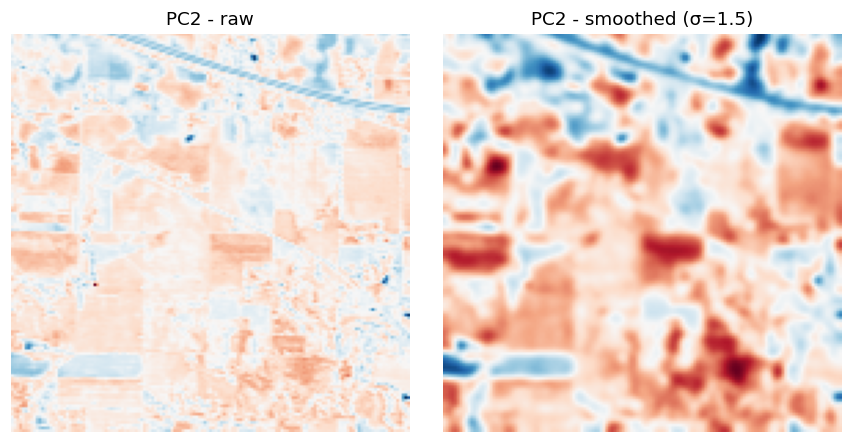

In [5]:
Z_sm = gaussian_filter(Z_img, sigma=(1.5, 1.5, 0)).reshape(N, N_PCA).astype(np.float32)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(Z_img[:, :, 1], cmap="RdBu_r"); ax[0].set_title("PC2 - raw")
ax[1].imshow(Z_sm.reshape(H, W, N_PCA)[:, :, 1], cmap="RdBu_r"); ax[1].set_title("PC2 - smoothed (σ=1.5)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Spectral unmixing with NMF
Non-negative Matrix Factorisation decomposes every pixel spectrum into a non-negative mix of a few
**endmember spectra**; the mixing weights are **abundance maps**. This is a classic unsupervised remote-sensing tool.

relative reconstruction error: 0.0314


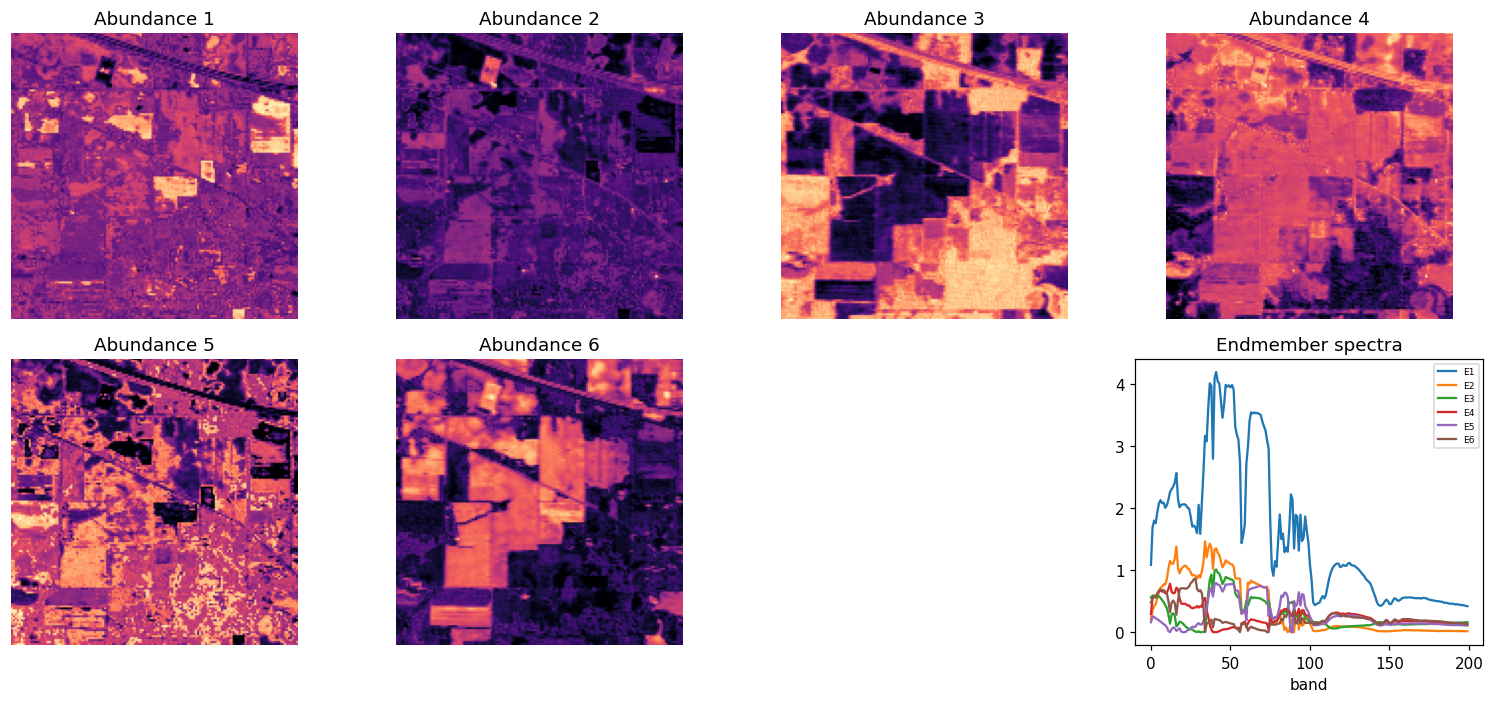

In [6]:
N_END = 6
X_nn = X_all / X_all.max()                      # non-negative, scaled to [0, 1]
nmf = NMF(n_components=N_END, init="nndsvda", max_iter=500, random_state=SEED)
A = nmf.fit_transform(X_nn)                     # abundances  (N, 6)
E = nmf.components_                             # endmembers  (6, 200)
print(f"relative reconstruction error: {np.linalg.norm(X_nn - A @ E) / np.linalg.norm(X_nn):.4f}")

fig, ax = plt.subplots(2, 4, figsize=(14, 6.5))
for j in range(N_END):
    a = ax.ravel()[j]; im = a.imshow(A[:, j].reshape(H, W), cmap="magma"); a.set_title(f"Abundance {j+1}"); a.axis("off")
ax.ravel()[6].axis("off")
ax.ravel()[7].plot(E.T); ax.ravel()[7].set_title("Endmember spectra"); ax.ravel()[7].set_xlabel("band")
ax.ravel()[7].legend([f"E{j+1}" for j in range(N_END)], fontsize=6)
plt.tight_layout(); plt.show()

# hard "dominant endmember" map as one more unsupervised partition
nmf_labels = A.argmax(1)

### 3.3 t-SNE (2-D visualisation of the pixel cloud)
Computed on a 4 000-pixel random subset; each point is coloured with its own false-colour RGB so you can see
whether visually similar pixels sit together.

t-SNE done in 16s


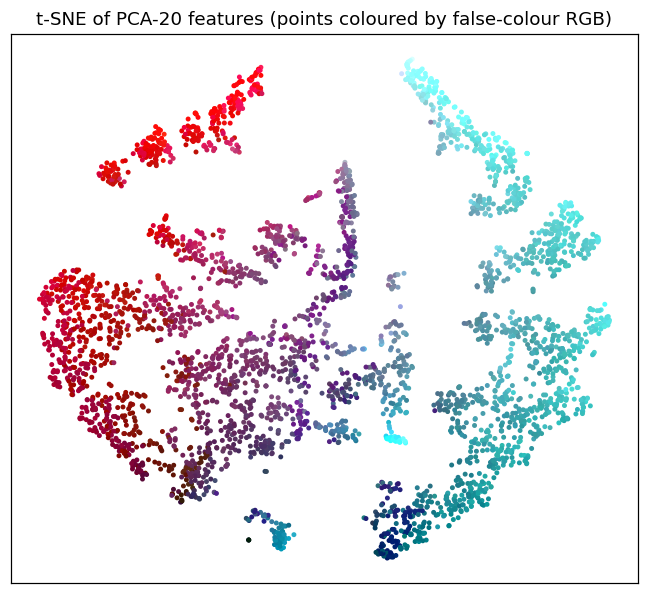

In [7]:
sub = np.random.RandomState(SEED).choice(N, 4000, replace=False)
t0 = time.time()
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z[sub])
print(f"t-SNE done in {time.time()-t0:.0f}s")
plt.figure(figsize=(6, 5.5))
plt.scatter(emb[:, 0], emb[:, 1], c=RGB.reshape(N, 3)[sub], s=5)
plt.title("t-SNE of PCA-20 features (points coloured by false-colour RGB)"); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

## 5. How many clusters? (label-free model selection)
K-Means is run for k = 2 … 20 and scored with four indices. Higher is better for **Silhouette** and **Calinski-Harabasz**;
lower is better for **Davies-Bouldin** and for the **inertia** "elbow".

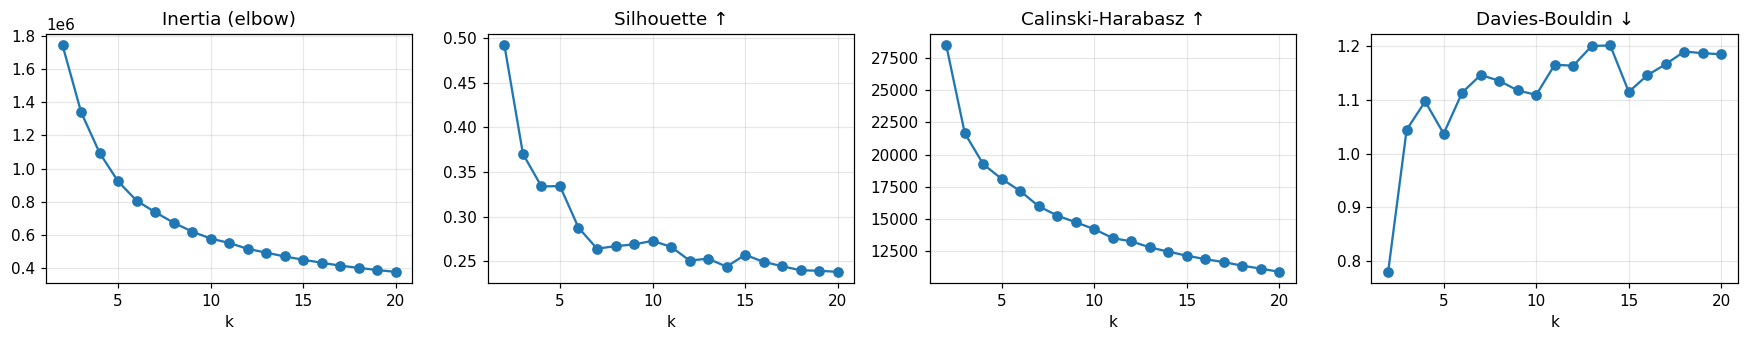

,inertia,silhouette,CH,DB
k,,,,
2,1740560.000,0.492,28484.487,0.779
3,1339314.250,0.370,21657.322,1.044
4,1093954.250,0.334,19247.195,1.097
5,922146.625,0.334,18103.152,1.037
6,806454.312,0.288,17162.427,1.114
7,737159.188,0.264,15975.049,1.146
8,674003.312,0.267,15256.625,1.136
9,620189.500,0.269,14735.146,1.118
10,578780.375,0.273,14201.410,1.109


In [8]:
rows = []
for k in range(2, 21):
    km = KMeans(k, n_init=3, random_state=SEED).fit(Z)
    rows.append(dict(k=k, inertia=km.inertia_,
                     silhouette=silhouette_score(Z, km.labels_, sample_size=4000, random_state=SEED),
                     CH=calinski_harabasz_score(Z, km.labels_), DB=davies_bouldin_score(Z, km.labels_)))
sweep = pd.DataFrame(rows).set_index("k")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, col, ttl in zip(ax, ["inertia", "silhouette", "CH", "DB"],
                       ["Inertia (elbow)", "Silhouette ↑", "Calinski-Harabasz ↑", "Davies-Bouldin ↓"]):
    a.plot(sweep.index, sweep[col], marker="o"); a.set_title(ttl); a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
display(sweep.round(3))

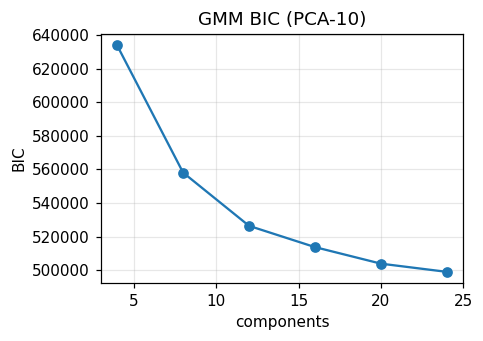

In [9]:
# Gaussian-mixture BIC (lower is better)
ks = [4, 8, 12, 16, 20, 24]
bic = [GaussianMixture(k, covariance_type="full", n_init=1, random_state=SEED, reg_covar=1e-4).fit(Z[:, :10]).bic(Z[:, :10]) for k in ks]
plt.figure(figsize=(4.5, 3.2)); plt.plot(ks, bic, marker="o"); plt.xlabel("components"); plt.ylabel("BIC")
plt.title("GMM BIC (PCA-10)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [10]:
# Internal indices usually prefer a small k, because spectrally similar crops genuinely overlap.
# The published Indian Pines ground truth has 16 land-cover classes, so 16 is used as the working value
# for the cluster maps below. Change K_FINAL freely - everything re-runs with it.
K_FINAL = 16

## 6. Clustering methods
All methods are compared in the **same PCA-20 feature space** so that the quality indices are comparable.

| # | Method | Idea |
|---|--------|------|
| 1 | K-Means | spherical clusters on PCA features |
| 2 | K-Means (brightness-normalised) | each spectrum is scaled to unit length first, so clusters follow spectral *shape* (similar in spirit to the Spectral Angle Mapper) |
| 3 | Gaussian Mixture | elliptical clusters, soft assignments |
| 4 | Ward + spatial connectivity | hierarchical merging, only adjacent pixels can merge, giving compact regions |
| 5 | Spatial-spectral K-Means | K-Means on the smoothed PCA images |
| 6 | HDBSCAN | density-based, finds the number of clusters itself and marks outliers as noise |

In [11]:
cl_labels, cl_table = {}, {}

def spatial_coherence(lab):
    """Fraction of 4-neighbour pixel pairs that share a cluster label (1 = perfectly smooth map)."""
    g = lab.reshape(H, W)
    same = np.concatenate([(g[:, 1:] == g[:, :-1]).ravel(), (g[1:, :] == g[:-1, :]).ravel()])
    return same.mean()

def register(name, lab, secs):
    lab = np.asarray(lab).astype(int)
    valid = lab >= 0
    ncl = len(np.unique(lab[valid]))
    sil = ch = db = np.nan
    if ncl >= 2:
        sil = silhouette_score(Z[valid], lab[valid], sample_size=min(4000, int(valid.sum())), random_state=SEED)
        ch = calinski_harabasz_score(Z[valid], lab[valid]); db = davies_bouldin_score(Z[valid], lab[valid])
    cl_labels[name] = lab
    cl_table[name] = dict(Clusters=ncl, Noise_pct=100 * (~valid).mean(), Silhouette=sil, CH=ch, DB=db,
                          Spatial_coherence=spatial_coherence(lab), Time_s=secs)
    r = cl_table[name]
    print(f"{name:<36} clusters={ncl:<3} silhouette={sil:.3f}  CH={ch:,.0f}  DB={db:.3f}  coherence={r['Spatial_coherence']:.3f}  ({secs:.1f}s)")

In [12]:
# 1) K-Means
t = time.time(); km1 = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Z)
register("K-Means", km1.labels_, time.time() - t)

# 2) K-Means on brightness-normalised spectra
t = time.time()
Xn = X_all / np.linalg.norm(X_all, axis=1, keepdims=True)
Zn = PCA(N_PCA, random_state=SEED).fit_transform(StandardScaler().fit_transform(Xn))
km2 = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Zn)
register("K-Means (brightness-normalised)", km2.labels_, time.time() - t)

# 3) Gaussian mixture
t = time.time()
gmm = GaussianMixture(K_FINAL, covariance_type="full", n_init=2, random_state=SEED, reg_covar=1e-4).fit(Z[:, :10])
gmm_labels = gmm.predict(Z[:, :10]); gmm_conf = gmm.predict_proba(Z[:, :10]).max(1)
register("Gaussian Mixture (PCA-10)", gmm_labels, time.time() - t)

K-Means                              clusters=16  silhouette=0.249  CH=11,866  DB=1.146  coherence=0.586  (1.0s)
K-Means (brightness-normalised)      clusters=16  silhouette=0.190  CH=9,355  DB=1.313  coherence=0.609  (1.0s)
Gaussian Mixture (PCA-10)            clusters=16  silhouette=0.129  CH=6,779  DB=1.538  coherence=0.544  (5.4s)


In [13]:
# 4) Ward hierarchical clustering restricted to spatially adjacent pixels
t = time.time()
conn = grid_to_graph(H, W)
ward = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward", connectivity=conn).fit(Z)
register("Ward + spatial connectivity", ward.labels_, time.time() - t)

# 5) Spatial-spectral K-Means (smoothed PCA features)
t = time.time(); km5 = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Z_sm)
register("Spatial-spectral K-Means", km5.labels_, time.time() - t)

Ward + spatial connectivity          clusters=16  silhouette=-0.108  CH=2,616  DB=5.347  coherence=0.929  (0.7s)
Spatial-spectral K-Means             clusters=16  silhouette=0.040  CH=6,033  DB=1.703  coherence=0.784  (1.2s)


In [14]:
# 6) HDBSCAN (density-based; -1 = noise)
if HDBSCAN_OK:
    t = time.time()
    hdb = HDBSCAN(min_cluster_size=100, min_samples=10).fit(Z_sm[:, :10])
    register("HDBSCAN (smoothed PCA-10)", hdb.labels_, time.time() - t)
else:
    print("HDBSCAN needs scikit-learn >= 1.3 (pip install -U scikit-learn) - skipped.")

HDBSCAN (smoothed PCA-10)            clusters=7   silhouette=0.060  CH=5,139  DB=1.545  coherence=0.887  (2.4s)


## 7. Comparing the results (no labels required)

In [15]:
tab = pd.DataFrame(cl_table).T
tab["Clusters"] = tab["Clusters"].astype(int)
display(tab.round(3))
tab.to_csv("clustering_metrics.csv")

,Clusters,Noise_pct,Silhouette,CH,DB,Spatial_coherence,Time_s
K-Means,16,0.00,0.249,11866.388,1.146,0.586,0.971
K-Means (brightness-normalised),16,0.00,0.190,9355.357,1.313,0.609,1.026
Gaussian Mixture (PCA-10),16,0.00,0.129,6778.853,1.538,0.544,5.396
Ward + spatial connectivity,16,0.00,-0.108,2616.024,5.347,0.929,0.702
Spatial-spectral K-Means,16,0.00,0.040,6032.874,1.703,0.784,1.202
HDBSCAN (smoothed PCA-10),7,40.59,0.060,5138.715,1.545,0.887,2.435


**Reading the table**
* *Silhouette* / *CH* / *DB* measure how compact and separated clusters are in feature space.
* *Spatial coherence* measures how smooth the cluster map is. Fields are large, so a good map should be high, while a score of 1.0 would mean one giant cluster.
* Methods that use spatial information will score higher on coherence and slightly lower on pure spectral indices. That trade-off is the point.
* Expect **Ward + spatial connectivity** to show a low or even negative silhouette: it is forced to merge only neighbouring pixels, so its regions overlap in spectral space. That is a property of the constraint, not a bug, and its map is the smoothest.
* **HDBSCAN** decides the number of clusters itself and labels low-density pixels as noise (black in the maps). A large *Noise_pct* is normal on this scene, and its silhouette is computed on the non-noise pixels only.

### 7.1 Cluster maps (colours matched across methods)

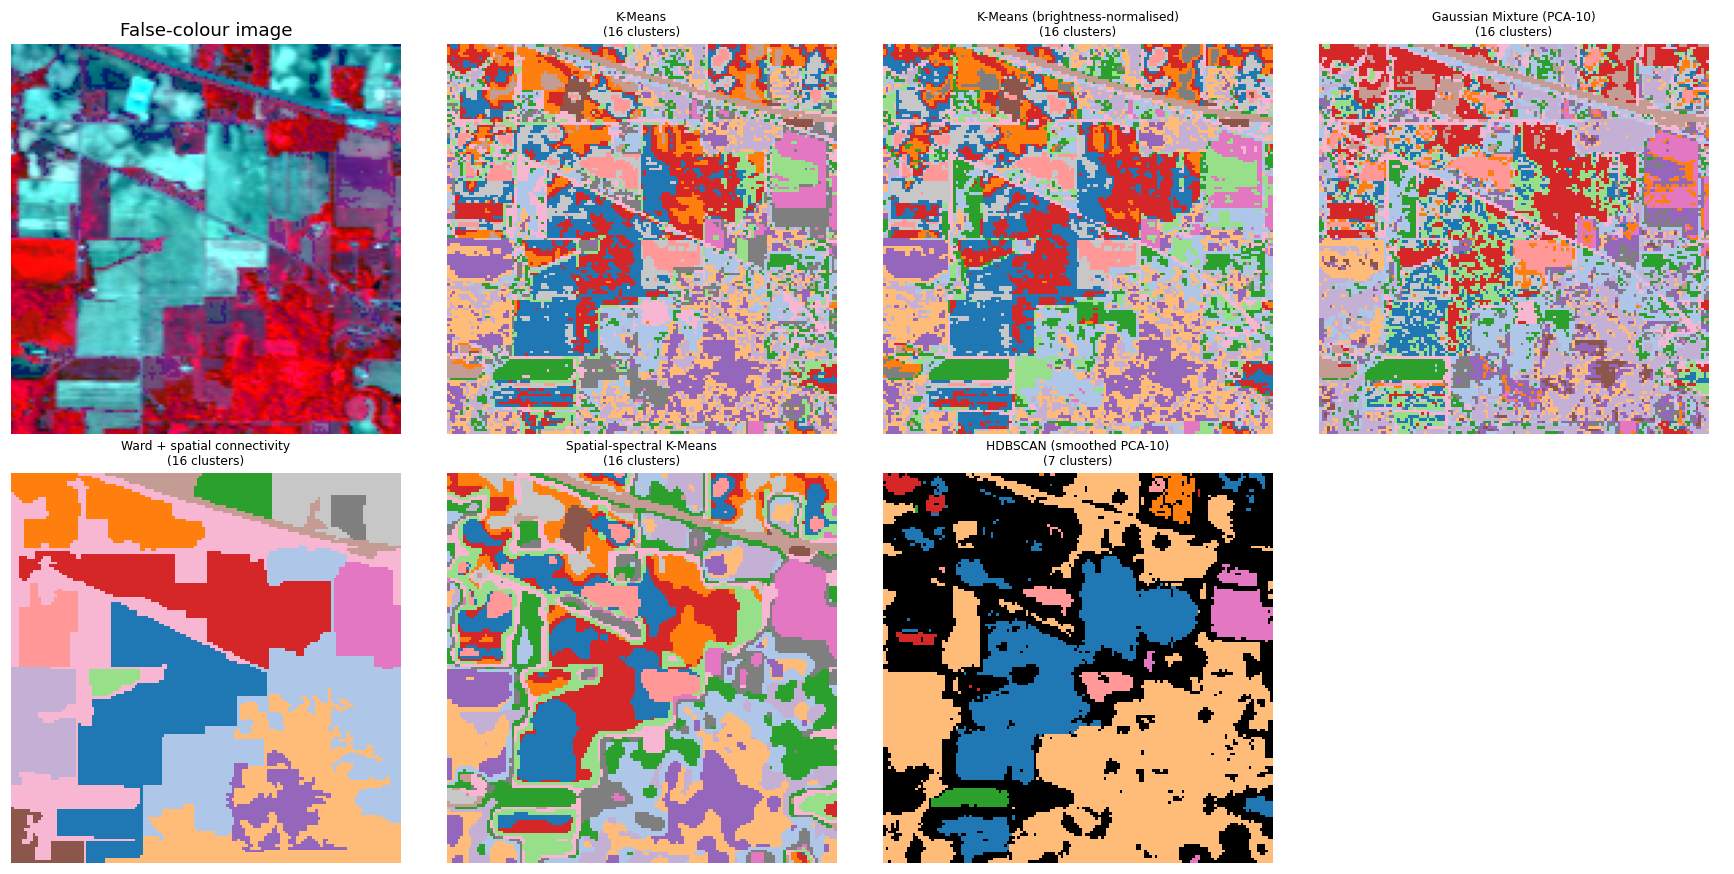

In [16]:
def align(ref, lab):
    """Relabel `lab` so that its clusters line up with the clusters of `ref` (Hungarian matching)."""
    out = lab.copy(); valid = lab >= 0
    kr, kl = ref.max() + 1, lab.max() + 1
    cont = np.zeros((kr, kl))
    for a, b in zip(ref[valid], lab[valid]): cont[a, b] += 1
    r_i, c_i = linear_sum_assignment(-cont)
    mapping = {c: r for r, c in zip(r_i, c_i)}
    nxt = kr
    for c in range(kl):
        if c not in mapping: mapping[c] = nxt; nxt += 1
    for c, r in mapping.items(): out[lab == c] = r
    return out

ref = cl_labels["K-Means"]
aligned = {n: (l if n == "K-Means" else align(ref, l)) for n, l in cl_labels.items()}
PALETTE = ["black"] + [plt.cm.tab20(i % 20) for i in range(60)]
cm_ = ListedColormap(PALETTE)

names = list(aligned)
ncol = 4; nrow = int(np.ceil((len(names) + 1) / ncol))
fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow))
ax = ax.ravel()
ax[0].imshow(RGB); ax[0].set_title("False-colour image")
for a, n in zip(ax[1:], names):
    a.imshow(aligned[n].reshape(H, W) + 1, cmap=cm_, vmin=0, vmax=len(PALETTE) - 1, interpolation="nearest")
    a.set_title(f"{n}\n({cl_table[n]['Clusters']} clusters)", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 7.2 How much do the methods agree?

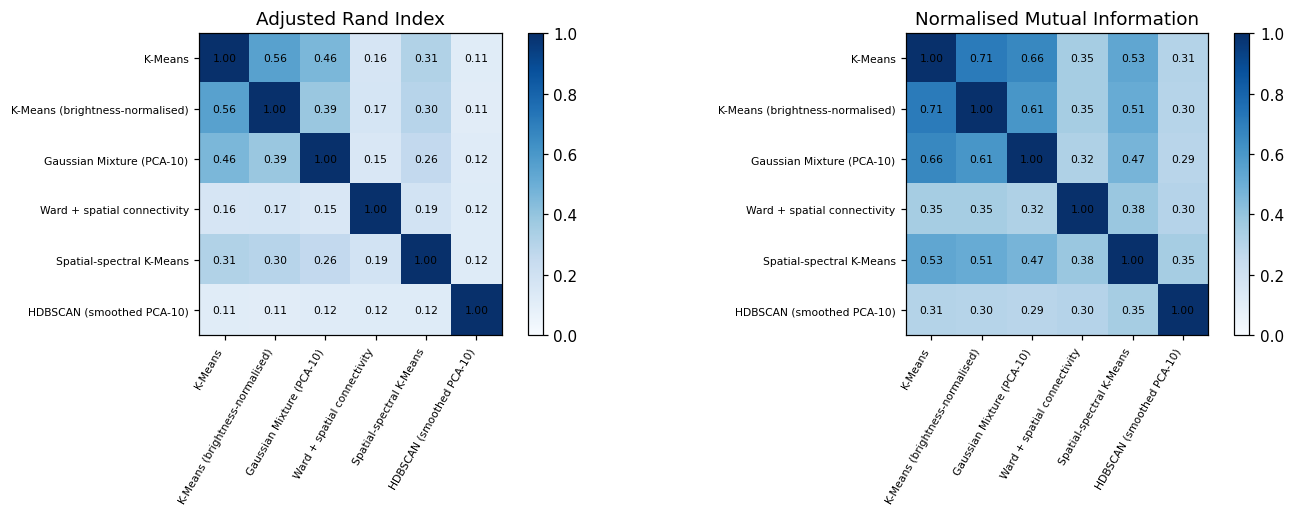

In [17]:
nm = list(cl_labels)
ari = pd.DataFrame([[adjusted_rand_score(cl_labels[a], cl_labels[b]) for b in nm] for a in nm], index=nm, columns=nm)
nmi = pd.DataFrame([[normalized_mutual_info_score(cl_labels[a], cl_labels[b]) for b in nm] for a in nm], index=nm, columns=nm)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, m, t in zip(ax, [ari, nmi], ["Adjusted Rand Index", "Normalised Mutual Information"]):
    im = a.imshow(m.values, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(len(nm))); a.set_yticks(range(len(nm)))
    a.set_xticklabels(nm, rotation=60, ha="right", fontsize=7); a.set_yticklabels(nm, fontsize=7)
    for i in range(len(nm)):
        for j in range(len(nm)): a.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    a.set_title(t); plt.colorbar(im, ax=a, fraction=.046)
plt.tight_layout(); plt.show()

### 7.3 Stability
K-Means depends on its random start. Here it is run 5 times with a single initialisation each and the partitions are
compared pairwise with the Adjusted Rand Index (1 = identical every time).

In [18]:
def stability(feat, k, seeds=(0, 1, 2, 3, 4)):
    labs = [KMeans(k, n_init=1, random_state=s).fit_predict(feat) for s in seeds]
    pairs = [adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))]
    return np.mean(pairs), np.std(pairs)

stab = {n: stability(f, K_FINAL) for n, f in [("K-Means", Z), ("Spatial-spectral K-Means", Z_sm)]}
display(pd.DataFrame(stab, index=["mean ARI", "std"]).T.round(3))

,mean ARI,std
K-Means,0.757,0.072
Spatial-spectral K-Means,0.740,0.069


### 7.4 Cluster profiles (K-Means)

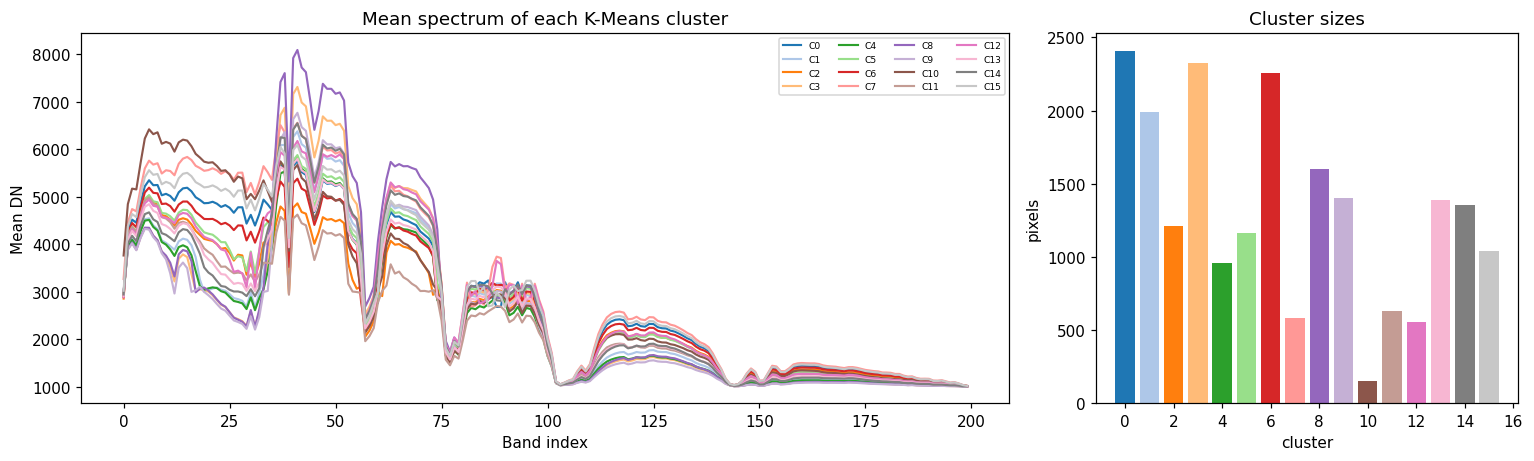

In [19]:
km_lab = cl_labels["K-Means"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [2.2, 1]})
for c in range(K_FINAL):
    ax[0].plot(X_all[km_lab == c].mean(0), color=PALETTE[c + 1], lw=1.4, label=f"C{c}")
ax[0].set_xlabel("Band index"); ax[0].set_ylabel("Mean DN"); ax[0].set_title("Mean spectrum of each K-Means cluster")
ax[0].legend(ncol=4, fontsize=6)
sizes = np.bincount(km_lab, minlength=K_FINAL)
ax[1].bar(range(K_FINAL), sizes, color=[PALETTE[c + 1] for c in range(K_FINAL)])
ax[1].set_xlabel("cluster"); ax[1].set_ylabel("pixels"); ax[1].set_title("Cluster sizes")
plt.tight_layout(); plt.show()

### 7.5 Clusters in t-SNE space, and GMM confidence

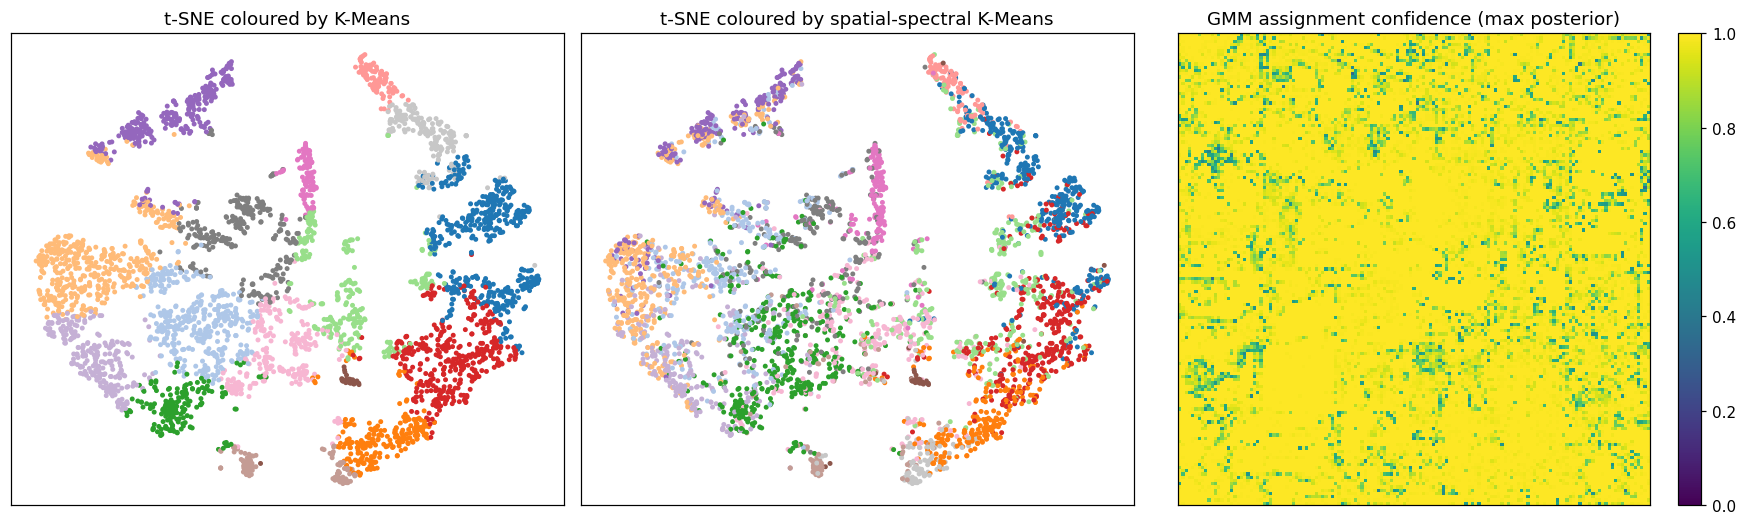

Mean GMM confidence: 0.963  | pixels with confidence < 0.8: 6.7%


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].scatter(emb[:, 0], emb[:, 1], c=[PALETTE[l + 1] for l in km_lab[sub]], s=5); ax[0].set_title("t-SNE coloured by K-Means")
sl = aligned["Spatial-spectral K-Means"]
ax[1].scatter(emb[:, 0], emb[:, 1], c=[PALETTE[l + 1] for l in sl[sub]], s=5); ax[1].set_title("t-SNE coloured by spatial-spectral K-Means")
im = ax[2].imshow(gmm_conf.reshape(H, W), cmap="viridis", vmin=0, vmax=1); ax[2].set_title("GMM assignment confidence (max posterior)")
plt.colorbar(im, ax=ax[2], fraction=.046)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print(f"Mean GMM confidence: {gmm_conf.mean():.3f}  | pixels with confidence < 0.8: {(gmm_conf < 0.8).mean()*100:.1f}%")

## 8. Export

In [21]:
out = pd.DataFrame({"row": np.repeat(np.arange(H), W), "col": np.tile(np.arange(W), H)})
for n, l in aligned.items(): out[n] = l
out.to_csv("clustering_results.csv", index=False)
print("Saved clustering_results.csv (per-pixel cluster ids for every method) and clustering_metrics.csv")
out.head()

Saved clustering_results.csv (per-pixel cluster ids for every method) and clustering_metrics.csv


,row,col,K-Means,K-Means (brightness-normalised),Gaussian Mixture (PCA-10),Ward + spatial connectivity,Spatial-spectral K-Means,HDBSCAN (smoothed PCA-10)
0,0,0,6,6,6,2,6,6
1,0,1,0,0,5,2,6,6
2,0,2,0,15,5,2,6,-1
3,0,3,0,0,5,2,6,6
4,0,4,6,6,6,2,2,6


### Optional: if you later obtain `Indian_pines_gt.mat`
Cluster labels can then be scored externally (ARI / NMI) without any change to the methods above. This cell does nothing if the file is absent.

In [22]:
if os.path.exists("Indian_pines_gt.mat"):
    gt = sio.loadmat("Indian_pines_gt.mat")["indian_pines_gt"].astype(int).ravel()
    m = gt > 0
    ext = pd.DataFrame({n: dict(ARI=adjusted_rand_score(gt[m], l[m]), NMI=normalized_mutual_info_score(gt[m], l[m]))
                        for n, l in cl_labels.items()}).T
    display(ext.round(3).sort_values("ARI", ascending=False))
else:
    print("No ground-truth file found - skipping (this is fine; everything above is label-free).")

No ground-truth file found - skipping (this is fine; everything above is label-free).


## 9. Notes for the report
* **What this is:** exploratory *cluster analysis*, not classification. Clusters have no class names. Interpret them by comparing the maps with the
  false-colour image and the cluster spectra (for example vegetation vs. bare soil vs. woods).
* **Do not report accuracy / Kappa.** Without labels they are undefined. Report silhouette, Calinski-Harabasz, Davies-Bouldin, spatial coherence,
  stability (ARI across seeds) and between-method agreement (ARI / NMI).
* **Choosing k:** internal indices usually favour a small k. Say explicitly that `K_FINAL = 16` was chosen to match the number of land-cover classes
  in the published scene, and show the sweep in section 5 to justify the trade-off.
* **Spatial information matters:** compare "K-Means" with "Spatial-spectral K-Means" and "Ward + spatial connectivity": maps become smoother and more field-like.
* **Limitations:** clusters can split one crop by illumination or soil differences, and merge crops with similar spectra (e.g. corn vs. soybean residue).
  K-Means assumes roughly spherical clusters; GMM and HDBSCAN relax this at higher cost or sensitivity to parameters.